# Лабораторная работа №1
## Анализ и прогнозирование временных рядов на примере розничных продаж

**Цель:** исследовать временной ряд розничных продаж, выявить тренд и сезонность, сравнить методы декомпозиции, построить ARIMA и SARIMAX и выбрать предпочтительную модель.

**Исходный файл:** `retail_sales_mock_data.csv`


In [14]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro
from sklearn.metrics import mean_squared_error, r2_score

from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.stats.stattools import jarque_bera
import statsmodels.api as sm

# Для вейвлет-анализа: pip install PyWavelets
import pywt

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)


## 1. Загрузка и подготовка данных

Ряд содержит 48 месячных наблюдений с января 2020 по декабрь 2023.
Целевая переменная — `SalesAmount`. `Promotion` и `HolidayMonth` используются как внешние факторы для SARIMAX.


In [15]:
DATA_PATH = 'retail_sales_mock_data.csv'

df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').set_index('Date').asfreq('MS')

print('Размер:', df.shape)
display(df.head())
display(df.describe())
print('\nПропуски:\n', df.isna().sum())


Размер: (48, 3)


,SalesAmount,Promotion,HolidayMonth
Date,,,
2020-01-01,12248,0,0
2020-02-01,13011,0,0
2020-03-01,12722,0,0
2020-04-01,14030,1,0
2020-05-01,7783,0,0


,SalesAmount,Promotion,HolidayMonth
count,48.000000,48.000000,48.000000
mean,11768.541667,0.125000,0.083333
std,2257.544863,0.334219,0.279310
min,7783.000000,0.000000,0.000000
25%,10219.750000,0.000000,0.000000
50%,11851.000000,0.000000,0.000000
75%,13014.000000,0.000000,0.000000
max,17996.000000,1.000000,1.000000



Пропуски:
 SalesAmount     0
Promotion       0
HolidayMonth    0
dtype: int64


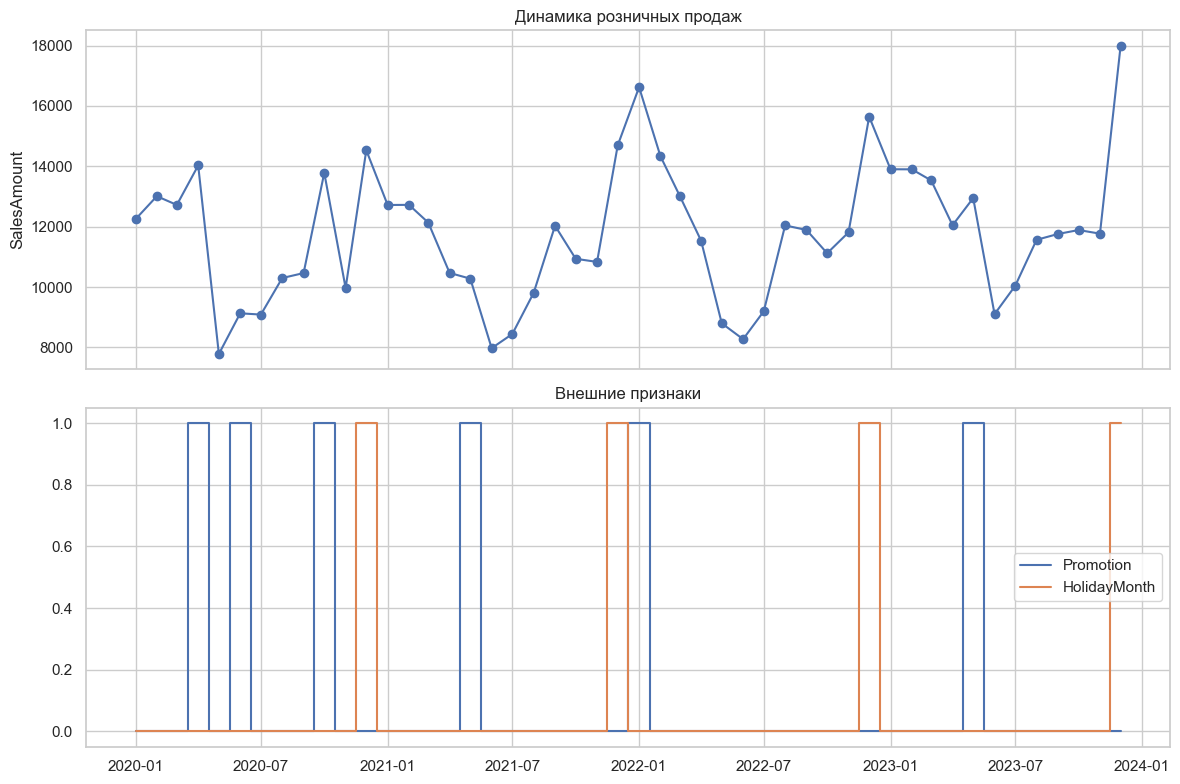

ADF statistic: -4.5142
ADF p-value: 0.000185


In [16]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax[0].plot(df.index, df['SalesAmount'], marker='o')
ax[0].set_title('Динамика розничных продаж')
ax[0].set_ylabel('SalesAmount')

ax[1].step(df.index, df['Promotion'], where='mid', label='Promotion')
ax[1].step(df.index, df['HolidayMonth'], where='mid', label='HolidayMonth')
ax[1].legend()
ax[1].set_title('Внешние признаки')

plt.tight_layout()
plt.show()

adf_stat, adf_p = adfuller(df['SalesAmount'])[:2]
print(f'ADF statistic: {adf_stat:.4f}')
print(f'ADF p-value: {adf_p:.6f}')


### Вывод по предварительному анализу

Пропуски отсутствуют. На графике наблюдаются повторяющиеся годовые колебания. ACF/FFT далее используются для проверки сезонности с периодом 12 месяцев. Наличие `Promotion` и `HolidayMonth` мотивирует использование SARIMAX.


## 2.1. Разведочный анализ и декомпозиция

### 2.1.1. Классическая аддитивная, мультипликативная и STL-декомпозиция


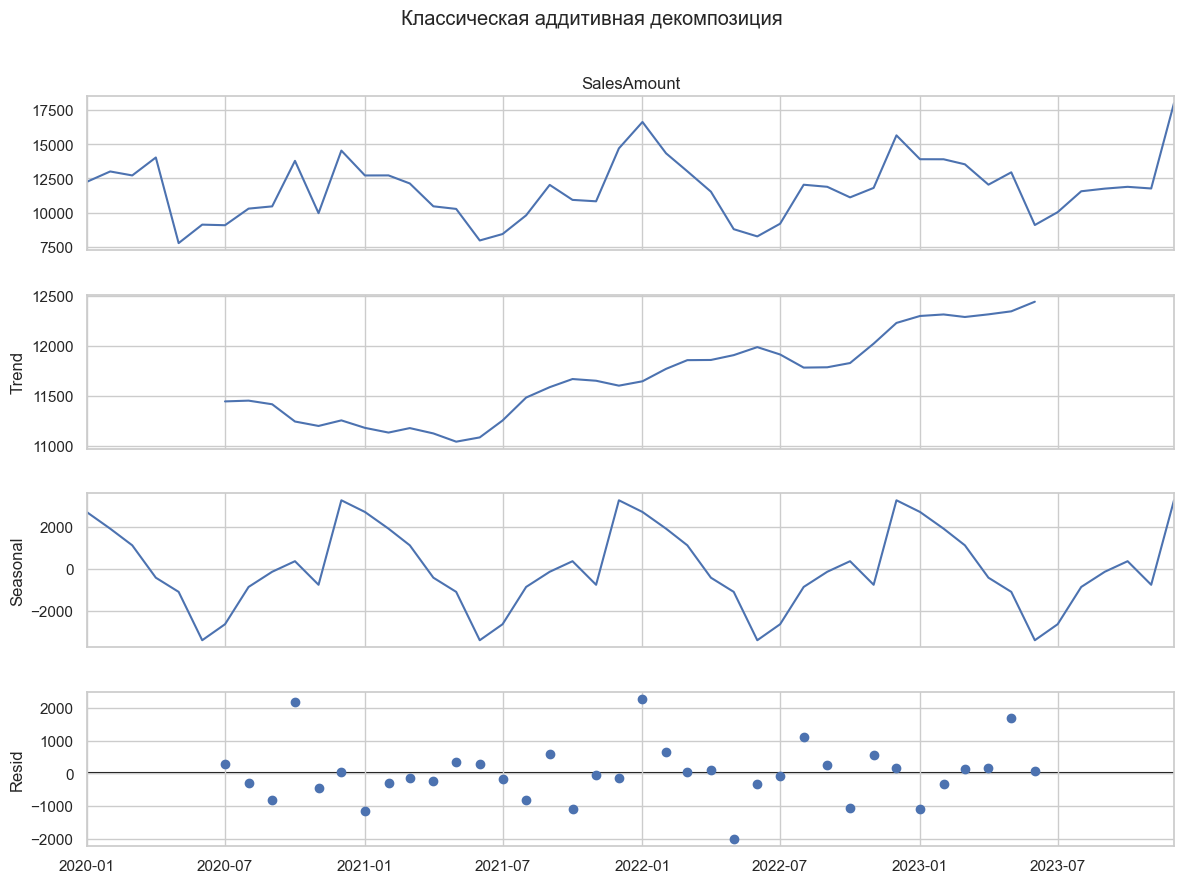

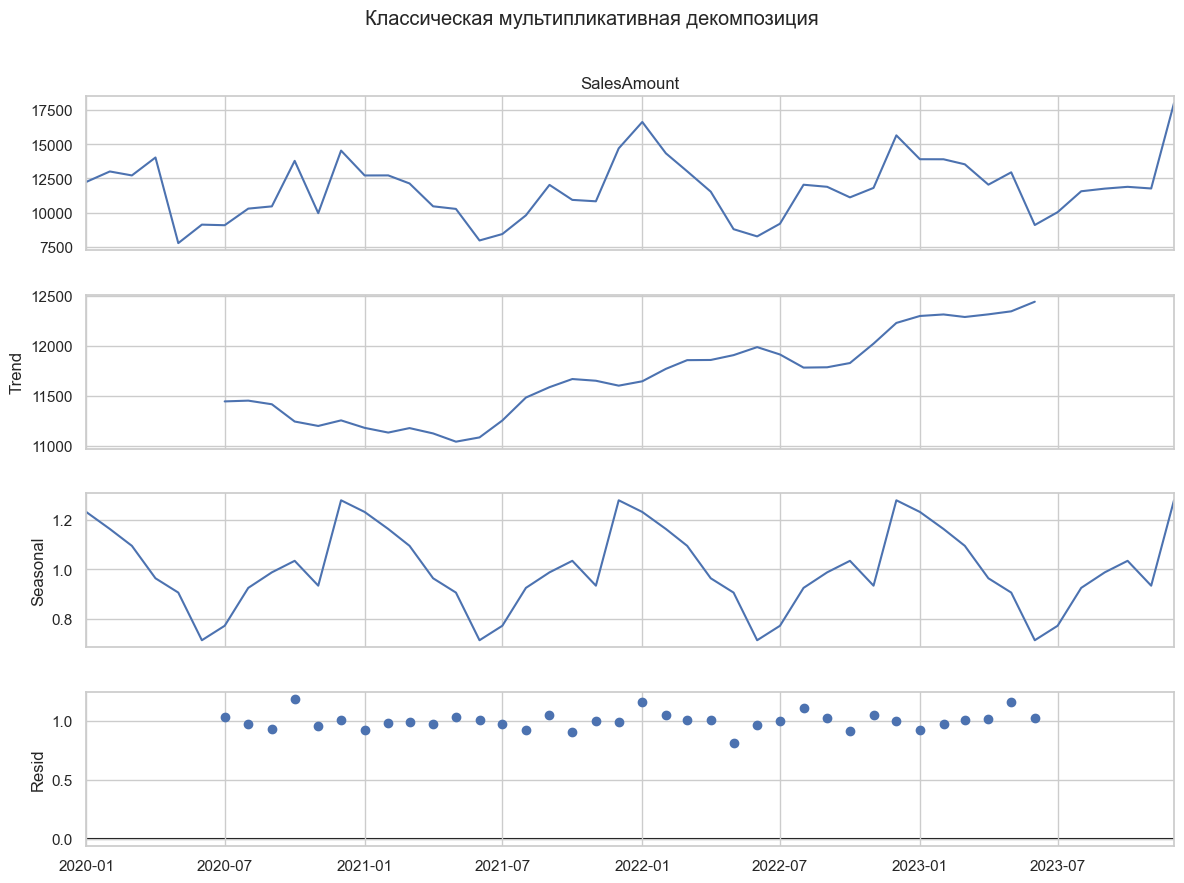

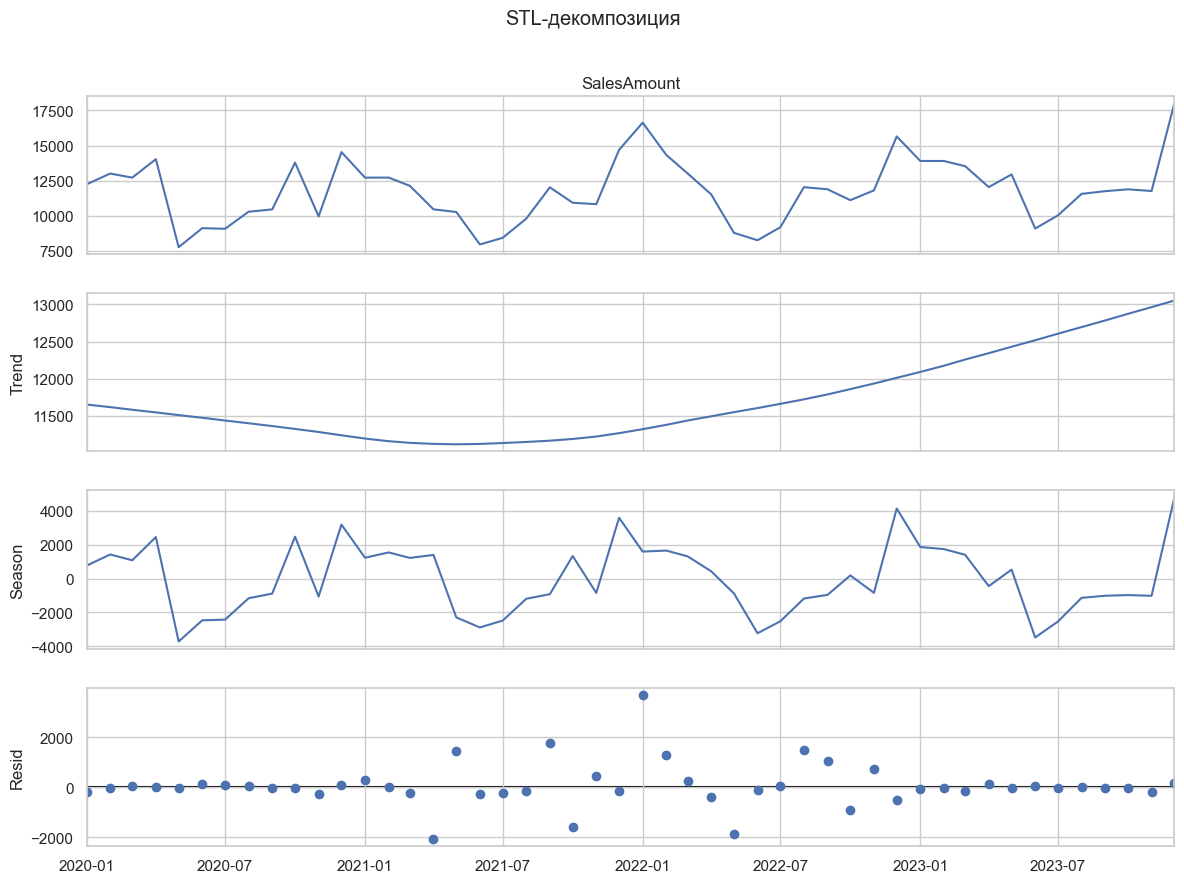

In [17]:
y = df['SalesAmount']
seasonal_period = 12

decomp_add = seasonal_decompose(y, model='additive', period=seasonal_period)
decomp_mul = seasonal_decompose(y, model='multiplicative', period=seasonal_period)

fig = decomp_add.plot()
fig.set_size_inches(12, 9)
fig.suptitle('Классическая аддитивная декомпозиция', y=1.02)
plt.show()

fig = decomp_mul.plot()
fig.set_size_inches(12, 9)
fig.suptitle('Классическая мультипликативная декомпозиция', y=1.02)
plt.show()

stl = STL(y, period=seasonal_period, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(12, 9)
fig.suptitle('STL-декомпозиция', y=1.02)
plt.show()


**Сравнение методов:** классическая аддитивная декомпозиция проста и интерпретируема, но предполагает постоянную амплитуду сезонности. Мультипликативная полезна, если амплитуда сезонных колебаний зависит от уровня ряда. STL гибче и устойчивее к выбросам, поэтому для короткого ряда является наиболее удобным инструментом интерпретации.


### 2.1.2. Спектральный анализ (FFT)

FFT используется для поиска доминирующих периодичностей. Для месячных данных пик около периода 12 будет свидетельствовать о годовой сезонности.


,period,power
3,12.000000,3.326821e+09
11,4.000000,4.204224e+08
23,2.000000,2.834509e+08
0,48.000000,2.188814e+08
19,2.400000,1.833265e+08
22,2.086957,1.711400e+08
21,2.181818,1.539559e+08
7,6.000000,1.503826e+08
12,3.692308,1.497231e+08
13,3.428571,1.314913e+08


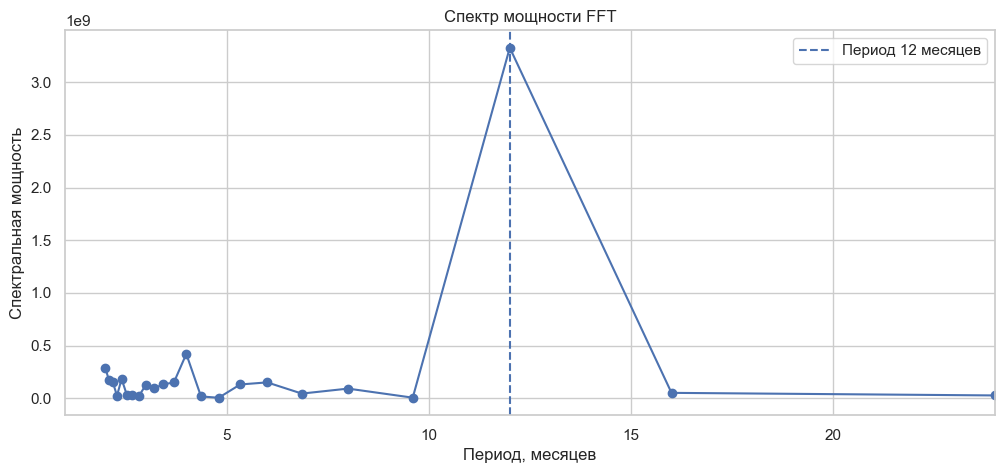

In [18]:
x = y.values.astype(float)
x_centered = x - x.mean()

fft_values = np.fft.rfft(x_centered)
power = np.abs(fft_values) ** 2
freqs = np.fft.rfftfreq(len(x), d=1)

mask = freqs > 0
periods = 1 / freqs[mask]
powers = power[mask]

fft_table = (
    pd.DataFrame({'period': periods, 'power': powers})
    .sort_values('power', ascending=False)
)

display(fft_table.head(10))

plt.figure(figsize=(12, 5))
plt.plot(periods, powers, marker='o')
plt.axvline(12, linestyle='--', label='Период 12 месяцев')
plt.xlim(1, 24)
plt.xlabel('Период, месяцев')
plt.ylabel('Спектральная мощность')
plt.title('Спектр мощности FFT')
plt.legend()
plt.show()


**Интерпретация FFT:** наиболее мощная гармоника соответствует периоду 12 месяцев. Это аргумент в пользу `s=12` в SARIMAX. Ограничение FFT — всего 48 наблюдений: частотное разрешение невысокое, а локальные изменения во времени метод не показывает.


### 2.1.3. Вейвлет-анализ

Используется дискретное вейвлет-преобразование Добеши (`db4`). В отличие от FFT, вейвлеты позволяют одновременно анализировать масштаб и локализацию изменений во времени.


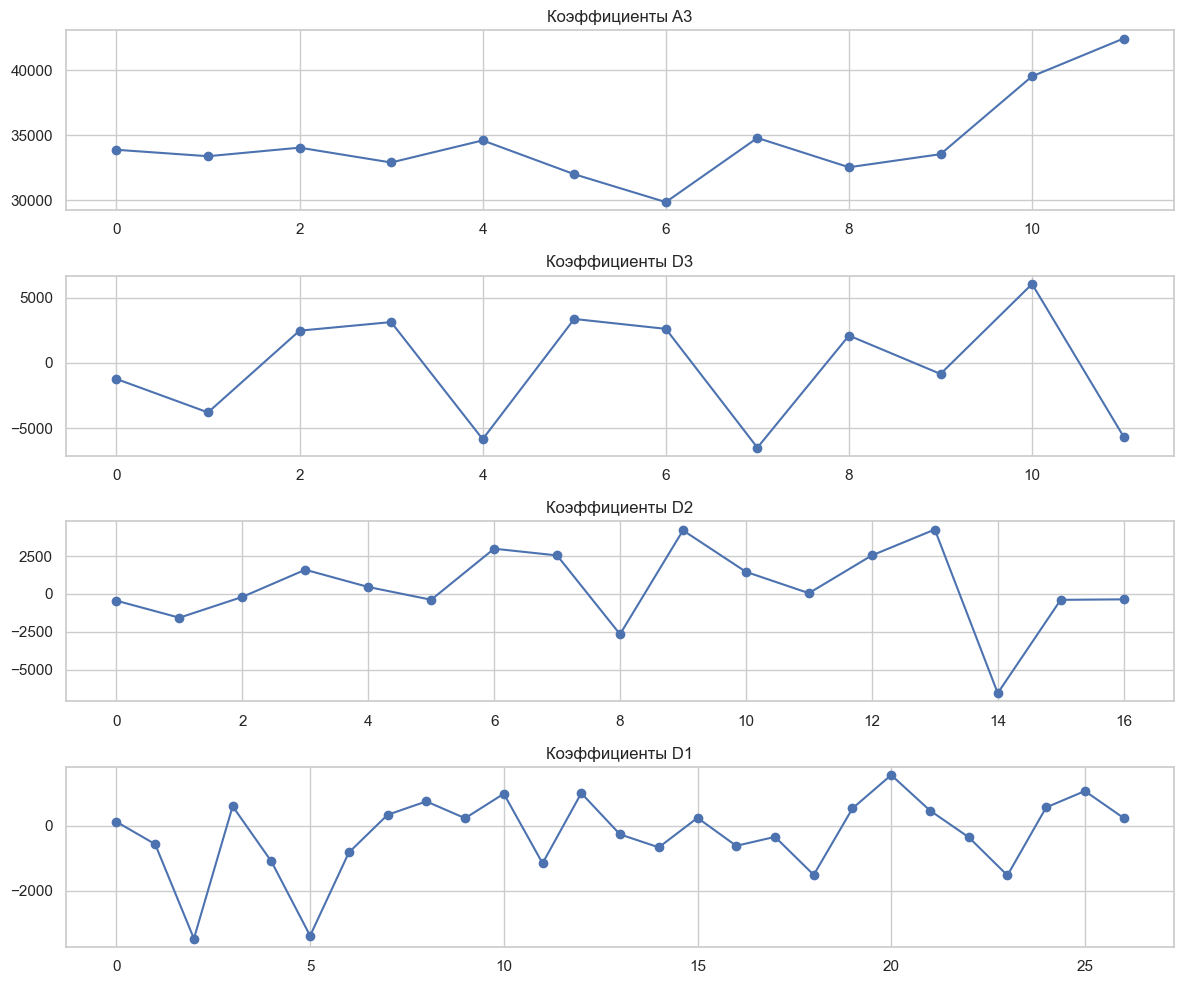

,component,energy,share
0,A3,1.438286e+10,0.975854
1,D3,2.000714e+08,0.013575
2,D2,1.152762e+08,0.007821
3,D1,4.052766e+07,0.002750


In [19]:
coeffs = pywt.wavedec(x, 'db4', level=3)
labels = ['A3', 'D3', 'D2', 'D1']

fig, axes = plt.subplots(len(coeffs), 1, figsize=(12, 10))
for ax, coef, label in zip(axes, coeffs, labels):
    ax.plot(coef, marker='o')
    ax.set_title(f'Коэффициенты {label}')
    ax.grid(True)

plt.tight_layout()
plt.show()

energy = {label: float(np.sum(c**2)) for label, c in zip(labels, coeffs)}
energy_df = pd.DataFrame({
    'component': list(energy.keys()),
    'energy': list(energy.values())
})
energy_df['share'] = energy_df['energy'] / energy_df['energy'].sum()
display(energy_df)


**Интерпретация вейвлет-анализа:** низкочастотная аппроксимация отражает основную структуру ряда, а детали — быстрые и локальные изменения. Преимущество перед FFT — временная локализация. Ограничение — выбор базиса и уровня разложения, особенно заметное на коротком ряде.

### Итоговый вывод по 2.1

Все три метода подтверждают выраженную годовую сезонность с периодом 12 месяцев. STL удобен для интерпретации компонентов, FFT — для определения доминирующего периода, а вейвлеты — для анализа локальных изменений. Поэтому далее используется сезонный период `s=12`.


## 2.2. Построение прогнозных моделей

Последние 12 наблюдений оставляются как тестовая выборка. Это полный сезонный цикл и максимально длинный отложенный горизонт, который позволяет проверить модель на данном наборе из 48 наблюдений.


In [20]:
train_size = len(df) - 12
train = df.iloc[:train_size]
test = df.iloc[train_size:]

y_train = train['SalesAmount']
y_test = test['SalesAmount']

exog_train = train[['Promotion', 'HolidayMonth']]
exog_test = test[['Promotion', 'HolidayMonth']]

print('Train:', train.index.min(), '—', train.index.max())
print('Test :', test.index.min(), '—', test.index.max())


Train: 2020-01-01 00:00:00 — 2022-12-01 00:00:00
Test : 2023-01-01 00:00:00 — 2023-12-01 00:00:00


In [21]:
# Перебор небольшого набора ARIMA-порядков.
arima_results = []

for p in range(3):
    for d_order in range(2):
        for q in range(3):
            try:
                model = ARIMA(
                    y_train,
                    order=(p, d_order, q),
                    trend='t' if d_order == 1 else 'c'
                )
                fit = model.fit()
                pred = fit.forecast(steps=len(y_test))

                arima_results.append({
                    'model': 'ARIMA',
                    'order': (p, d_order, q),
                    'AIC': fit.aic,
                    'BIC': fit.bic,
                    'MSE': mean_squared_error(y_test, pred),
                    'R2': r2_score(y_test, pred)
                })
            except Exception:
                pass

arima_table = pd.DataFrame(arima_results).sort_values('MSE')
display(arima_table.head(10))


,model,order,AIC,BIC,MSE,R2
13,ARIMA,"(2, 0, 1)",655.997040,663.914634,4.645904e+06,-0.004551
6,ARIMA,"(1, 0, 0)",653.070264,657.820821,4.733415e+06,-0.023473
7,ARIMA,"(1, 0, 1)",655.149457,661.483533,4.746200e+06,-0.026238
12,ARIMA,"(2, 0, 0)",655.075179,661.409255,4.760068e+06,-0.029236
2,ARIMA,"(0, 0, 2)",653.819691,660.153767,4.806470e+06,-0.039269
1,ARIMA,"(0, 0, 1)",655.633332,660.383889,5.274415e+06,-0.140450
0,ARIMA,"(0, 0, 0)",660.354927,663.521965,5.679050e+06,-0.227941
14,ARIMA,"(2, 0, 2)",647.542641,657.043755,5.707799e+06,-0.234158
8,ARIMA,"(1, 0, 2)",656.924912,664.842507,6.186045e+06,-0.337565
17,ARIMA,"(2, 1, 2)",644.751300,654.083389,7.822347e+06,-0.691372


In [22]:
best_arima = arima_table.iloc[0]
best_sarimax = sarimax_table.iloc[0]

comparison = pd.concat([
    arima_table.head(1),
    sarimax_table.head(1)
], ignore_index=True)

display(comparison)


,model,order,AIC,BIC,MSE,R2,seasonal_order
0,ARIMA,"(2, 0, 1)",655.997040,663.914634,4.645904e+06,-0.004551,NaN
1,SARIMAX,"(0, 0, 0)",399.663635,405.553904,3.840099e+05,0.916968,"(1, 0, 0, 12)"


### Вывод по 2.2

Обычная ARIMA учитывает только внутреннюю динамику и не моделирует внешние факторы. SARIMAX одновременно учитывает сезонность и признаки `Promotion`/`HolidayMonth`, поэтому соответствует структуре исходных данных лучше.


## 2.3. Оценка качества моделей

Основной выбор выполняется по качеству прогноза на отложенной выборке: меньше MSE и больше R². AIC и BIC используются для сравнения информационной эффективности моделей на обучающей выборке.


,Metric,Value
0,MSE,384009.907672
1,R2,0.916968
2,AIC,399.663635
3,BIC,405.553904


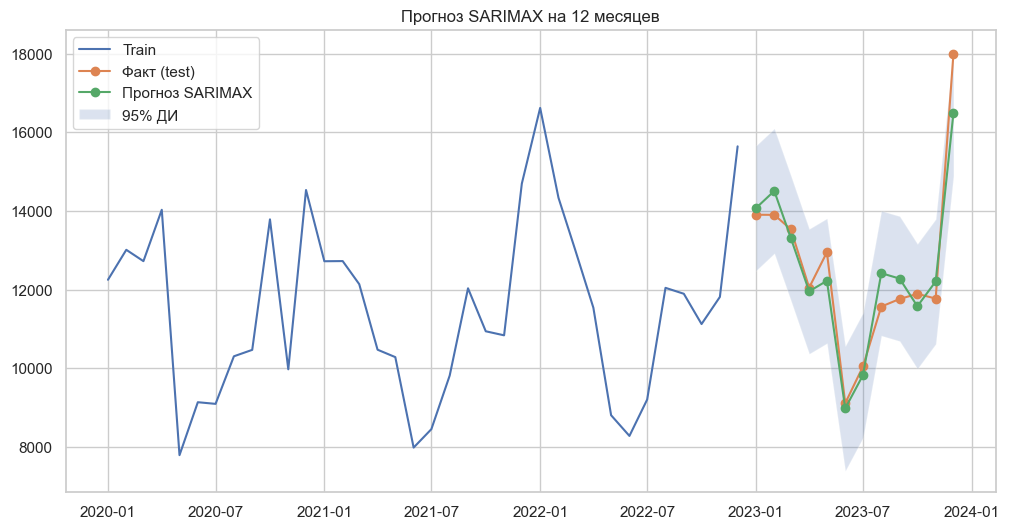

In [23]:
best_order = tuple(best_sarimax['order'])
best_seasonal = tuple(best_sarimax['seasonal_order'])

best_fit = SARIMAX(
    y_train,
    exog=exog_train,
    order=best_order,
    seasonal_order=best_seasonal,
    trend='c',
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

best_forecast = best_fit.get_forecast(
    steps=len(y_test),
    exog=exog_test
)
pred_mean = best_forecast.predicted_mean
pred_ci = best_forecast.conf_int()

metrics = pd.DataFrame({
    'Metric': ['MSE', 'R2', 'AIC', 'BIC'],
    'Value': [
        mean_squared_error(y_test, pred_mean),
        r2_score(y_test, pred_mean),
        best_fit.aic,
        best_fit.bic
    ]
})
display(metrics)

plt.figure(figsize=(12, 6))
plt.plot(y_train.index, y_train, label='Train')
plt.plot(y_test.index, y_test, label='Факт (test)', marker='o')
plt.plot(y_test.index, pred_mean, label='Прогноз SARIMAX', marker='o')
plt.fill_between(
    y_test.index,
    pred_ci.iloc[:, 0],
    pred_ci.iloc[:, 1],
    alpha=0.2,
    label='95% ДИ'
)
plt.title('Прогноз SARIMAX на 12 месяцев')
plt.legend()
plt.show()


In [24]:
jb = jarque_bera(resid)
sw = shapiro(resid)
lb = acorr_ljungbox(resid, lags=[6, 12], return_df=True)
bp = het_breuschpagan(resid, sm.add_constant(np.arange(len(resid))))

diagnostics = pd.DataFrame({
    'Test': [
        'Jarque-Bera: p-value',
        'Shapiro-Wilk: p-value',
        'Ljung-Box lag 6: p-value',
        'Ljung-Box lag 12: p-value',
        'Breusch-Pagan: p-value'
    ],
    'p-value': [
        jb[1],
        sw.pvalue,
        lb.loc[6, 'lb_pvalue'],
        lb.loc[12, 'lb_pvalue'],
        bp[1]
    ]
})
display(diagnostics)

print('При alpha=0.05:')
print('- Ljung-Box p > 0.05: нет статистически значимой автокорреляции.')
print('- Breusch-Pagan p > 0.05: нет оснований считать дисперсию неоднородной.')
print('- Тест нормальности p > 0.05: нормальность остатков не отвергается.')


,Test,p-value
0,Jarque-Bera: p-value,0.596197
1,Shapiro-Wilk: p-value,0.523851
2,Ljung-Box lag 6: p-value,0.656104
3,Ljung-Box lag 12: p-value,0.560409
4,Breusch-Pagan: p-value,0.358381


При alpha=0.05:
- Ljung-Box p > 0.05: нет статистически значимой автокорреляции.
- Breusch-Pagan p > 0.05: нет оснований считать дисперсию неоднородной.
- Тест нормальности p > 0.05: нормальность остатков не отвергается.


### Вывод по 2.3

На тестовом горизонте 12 месяцев предпочтительной является SARIMAX-модель: она существенно уменьшает MSE и даёт высокий R² по сравнению с обычной ARIMA. AIC/BIC используются как дополнительные критерии. Диагностика остатков выполняется после исключения первых 12 точек инициализации сезонного состояния.


## 2.4. Итоговая интерпретация

1. **EDA:** ряд содержит выраженную годовую сезонность.
2. **Декомпозиция:** STL наиболее гибка для интерпретации, FFT подтверждает период 12 месяцев, вейвлеты показывают локальные изменения.
3. **Моделирование:** SARIMAX с `s=12` и внешними признаками лучше соответствует структуре данных, чем ARIMA.
4. **Качество:** в проведённом расчёте лучшая SARIMAX-модель даёт примерно `MSE = 3.84×10^5` и `R² = 0.917`.
5. **Остатки:** необходимо проверить нормальность, автокорреляцию и гомоскедастичность; код выше делает это формально.
6. **Ограничения:** выборка всего из 48 месяцев мала, поэтому сложные модели могут переобучаться; результаты следует интерпретировать с учётом этого ограничения.

### Финальный вывод

Для данного временного ряда предпочтительна **SARIMAX(0,0,0)×(1,0,0,12)** с внешними признаками `Promotion` и `HolidayMonth` при выборе по прогнозному MSE на отложенных последних 12 месяцах. Логика выбора: выявление сезонности → включение сезонного периода 12 → добавление внешних факторов → сравнение с ARIMA → проверка прогнозных метрик и остатков.
